# DSMarket — Del pronóstico al estante: política de abastecimiento

**De:** Nicole, Data Science
**Para:** Paul (Director Financiero), Michelle (Chief Digital Officer)

Las tres tareas anteriores terminaron en un pronóstico. Un pronóstico, por sí solo, no repone nada: alguien tiene que decidir **cuántas unidades pedir, de qué producto, para qué tienda y con qué frecuencia**. Este documento propone cómo convertir las predicciones en esa decisión, y —más importante— **cuantifica cuánto vale hacerlo bien**.

La estructura es: primero la teoría que gobierna la decisión (secciones 2 y 3), después la propuesta concreta simulada sobre datos reales (4 a 7), y al final el diseño de cómo llevarlo a producción y escalarlo (8 y 9).

Una aclaración de alcance desde el principio: DSMarket no nos dio datos de costes, márgenes ni plazos de entrega. Todo lo que sigue usa **supuestos explícitos y parametrizados**, y la sección 6 muestra exactamente cuánto cambia la recomendación si esos supuestos cambian. Es la parte que hay que validar con Finanzas antes de aplicar nada.

## 1. Configuración

In [1]:
import os, pickle, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from scipy.stats import norm
warnings.filterwarnings('ignore')

DATA_DIR = "data_dsmarket/data_dsmarket"
CACHE = "cache_forecast"
pd.set_option('display.max_columns', 60)
%matplotlib inline

DSMARKET_NAVY = "#0a2a5c"; DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"; DSMARKET_GREEN = "#6a9f1f"
DSMARKET_BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
dsmarket_blues_cmap = LinearSegmentedColormap.from_list("dsmarket_blues", DSMARKET_BLUE_RAMP)
sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "figure.facecolor": "white", "axes.facecolor": "white"})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"

## 2. El marco teórico: qué decisión estamos tomando realmente

### 2.1. El problema del vendedor de diarios

La decisión de reposición es, en su forma más simple, el problema clásico del **newsvendor**: pedir una cantidad hoy sin saber la demanda de mañana, sabiendo que quedarse corto y quedarse largo cuestan cosas distintas.

- **Coste de faltante** ($C_u$, *underage*): el margen que se pierde cuando el cliente quiere el producto y no está. En retail hay además un coste de reputación difícil de medir.
- **Coste de sobrante** ($C_o$, *overage*): el capital inmovilizado, el espacio de góndola, y —si el producto es perecedero— la merma.

El resultado central de la teoría es que la cantidad óptima no es la demanda esperada, sino un **percentil** de la distribución de demanda:

$$\text{Nivel de servicio óptimo} = \frac{C_u}{C_u + C_o}$$

Esto es lo que justifica todo el trabajo de la Tarea 3 sobre intervalos de predicción: **stockear a la predicción media es óptimo solo si faltante y sobrante cuestan exactamente lo mismo**, cosa que casi nunca ocurre. En la Tarea 3 medimos que la predicción media cubre apenas el 67,8% de la demanda real — es decir, que la política de "pedir lo que dice el pronóstico" acepta implícitamente un 32% de faltantes.

### 2.2. Stock de seguridad: por qué la fórmula del manual no sirve tal cual

La fórmula clásica del stock de seguridad es $SS = z_{\alpha} \cdot \sigma_{L} $, donde $\sigma_L$ es el desvío de la demanda durante el plazo de cobertura y $z_\alpha$ el valor de la normal para el nivel de servicio buscado. Tiene dos supuestos que en este catálogo se rompen:

1. **Supone demanda normal.** La demanda de estos productos es asimétrica y discreta: en la Tarea 2 vimos que hay segmentos con 66% de días sin ninguna venta. Una normal ajustada a eso da stocks negativos en la cola izquierda y subestima la derecha.
2. **Supone que $\sigma$ es estable y se estima del pasado.** Pero el desvío cambia con el día de la semana, la temporada y el precio — justamente lo que el modelo de la Tarea 3 aprende.

Nuestra propuesta usa el **modelo cuantílico** entrenado en la Tarea 3 para estimar la dispersión: en vez de calcular $\sigma$ del histórico, la derivamos de la distancia entre el percentil 90 predicho y la media predicha, $\sigma_t = (p90_t - \mu_t)/z_{0.90}$. Así la dispersión es **condicional**: cambia día a día según lo que el modelo sabe de ese producto en ese momento.

La sección 7 pone a prueba si esto realmente sirve, y el resultado no es el que esperábamos.

### 2.3. La política: revisión periódica (R, S)

Elegimos una política de **revisión periódica con nivel de reposición**, la estándar en retail con entregas programadas:

- Cada **R = 7 días** se revisa el inventario de cada producto en cada tienda.
- Se pide lo necesario para llevar la posición de stock (inventario en tienda + pedidos en camino) hasta un **nivel objetivo S**.
- El pedido tarda **L = 2 días** en llegar.

El nivel objetivo tiene que cubrir la demanda de todo el período en que la decisión queda comprometida, que es el ciclo de revisión más el plazo de entrega — **R + L = 9 días**:

$$S = \underbrace{\sum_{i=1}^{R+L} \mu_i}_{\text{demanda esperada}} + \underbrace{z_{\alpha}\sqrt{\sum_{i=1}^{R+L}\sigma_i^2}}_{\text{stock de seguridad}}$$

*(La suma de varianzas asume independencia entre días. Es una simplificación: si la demanda está autocorrelacionada, subestima la dispersión real. Lo retomamos en la sección 7, porque resultó importar más de lo previsto.)*

## 3. Segmentar antes de decidir: ABC × XYZ

Aplicar la misma política a 30.490 combinaciones producto-tienda sería un error: no todas merecen la misma atención ni el mismo nivel de servicio. La segmentación estándar en gestión de inventarios cruza dos ejes:

- **ABC — por valor.** A: el 80% de la facturación. B: el 15% siguiente. C: el 5% restante.
- **XYZ — por predictibilidad**, medida con el coeficiente de variación de la demanda diaria. X: estable. Y: variable. Z: errática.

La gracia del cruce es que las dos preguntas son independientes: un producto puede facturar mucho y ser impredecible (AZ), o facturar poco y ser regular (CX). Y cada celda pide una política distinta.

In [2]:
V = np.load(f"{CACHE}/V_ventas.npy") if os.path.exists(f"{CACHE}/V_ventas.npy") else None
if V is None:      # primera ejecución: reconstruimos la matriz de ventas desde el CSV original
    sales = pd.read_csv(f"{DATA_DIR}/item_sales.csv")
    day_cols = [c for c in sales.columns if c.startswith('d_')]
    V = sales[day_cols].to_numpy(dtype=np.int16)
    np.save(f"{CACHE}/V_ventas.npy", V)
    sales_meta = sales[['id','item','category','department','store','store_code','region']]
    sales_meta.to_csv(f"{CACHE}/meta.csv", index=False)
    del sales
meta = pd.read_csv(f"{CACHE}/meta.csv")
calendar = pd.read_csv(f"{DATA_DIR}/daily_calendar_with_events.csv")
calendar['date'] = pd.to_datetime(calendar['date'])
clusters_prod = pd.read_csv(f"{CACHE}/clusters_producto.csv", index_col=0)
meta['cluster_k5'] = meta['item'].map(clusters_prod['cluster_k5'])

n_series, n_days = V.shape
s, e = n_days - 28, n_days                       # ventana de simulación = fold 3 de la Tarea 3
H = e - s
demanda = V[:, s:e].astype(np.float64)
media_pred = pickle.load(open(f"{CACHE}/pred2_fold2.pkl", "rb"))['pred_lgb'].astype(np.float64)
p90_pred = np.load(f"{CACHE}/p90_eval.npy").astype(np.float64)
print(f"ventana simulada: {calendar['date'].iloc[s].date()} a {calendar['date'].iloc[e-1].date()} ({H} días)")
print(f"series: {n_series:,} | demanda real del período: {demanda.sum():,.0f} unidades")

ventana simulada: 2016-03-28 a 2016-04-24 (28 días)
series: 30,490 | demanda real del período: 1,183,626 unidades


In [3]:
# precio medio de cada serie en la ventana (para valorizar), reconstruido igual que en la Tarea 3
prices = pd.read_csv(f"{DATA_DIR}/item_prices.csv").dropna(subset=['yearweek'])
prices['yearweek'] = prices['yearweek'].astype(int)
fila_de = pd.Series(np.arange(len(meta)), index=(meta['item'] + '|' + meta['store_code']).values)
prices['row'] = (prices['item'] + '|' + prices['store_code']).map(fila_de).astype(np.int32)
semanas = np.sort(prices['yearweek'].unique())
n_weeks = int(np.ceil(n_days / 7))
prices['widx'] = prices['yearweek'].map({w: i for i, w in enumerate(semanas)}) - (len(semanas) - n_weeks)
pw = prices[prices['widx'] >= 0]
P_week = np.full((n_series, n_weeks), np.nan, dtype=np.float32)
P_week[pw['row'].values, pw['widx'].values] = pw['sell_price'].values.astype(np.float32)
P = np.repeat(P_week, 7, axis=1)[:, :n_days]
del P_week, prices, pw

precio = np.nanmean(P[:, s:e], axis=1)
precio = np.where(np.isnan(precio), np.nanmedian(precio), precio)
activo = ~np.isnan(P[:, s:e]).all(axis=1)
print(f"series activas en la ventana: {activo.sum():,} de {n_series:,}")

series activas en la ventana: 30,490 de 30,490


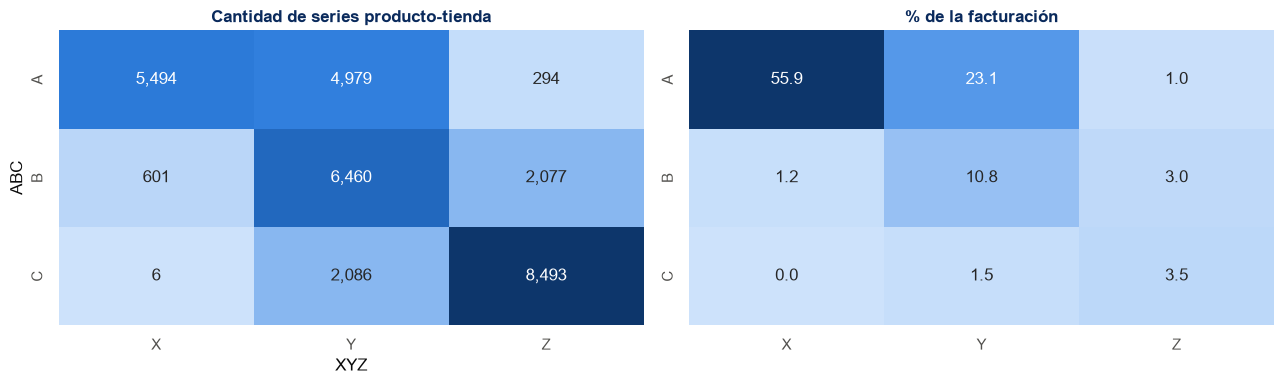

In [4]:
hist90 = V[:, s-90:s].astype(np.float64)
facturacion = hist90.sum(axis=1) * precio
orden = np.argsort(-facturacion)
acumulado = np.cumsum(facturacion[orden]) / facturacion.sum()
clase_abc = np.empty(n_series, dtype='<U1')
clase_abc[orden] = np.where(acumulado <= 0.80, 'A', np.where(acumulado <= 0.95, 'B', 'C'))

mu90, sd90 = hist90.mean(axis=1), hist90.std(axis=1)
cv = np.where(mu90 > 0, sd90 / np.maximum(mu90, 1e-9), 99.0)
clase_xyz = np.where(cv <= 1.0, 'X', np.where(cv <= 2.0, 'Y', 'Z'))
celda = np.char.add(clase_abc, clase_xyz)

tabla = pd.crosstab(pd.Series(clase_abc[activo], name='ABC'), pd.Series(clase_xyz[activo], name='XYZ'))
fac = (pd.Series(facturacion[activo]).groupby([pd.Series(clase_abc[activo]), pd.Series(clase_xyz[activo])])
       .sum().unstack() / facturacion[activo].sum() * 100)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.heatmap(tabla, annot=True, fmt=',d', cmap=dsmarket_blues_cmap, cbar=False, ax=axes[0])
axes[0].set_title('Cantidad de series producto-tienda', color=DSMARKET_NAVY, fontweight='bold')
sns.heatmap(fac, annot=True, fmt='.1f', cmap=dsmarket_blues_cmap, cbar=False, ax=axes[1])
axes[1].set_title('% de la facturación', color=DSMARKET_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

In [5]:
NOM_ARQ = {0: '0 · Premium', 1: '1 · Núcleo estable', 2: '2 · Cola larga',
           3: '3 · Fin de semana', 4: '4 · Fin de año'}
cruce = pd.crosstab(pd.Series([NOM_ARQ[c] for c in meta['cluster_k5'].values[activo]], name='arquetipo (Tarea 2)'),
                    pd.Series(clase_xyz[activo], name='XYZ'), normalize='index') * 100
cruce.round(1)

XYZ,X,Y,Z
arquetipo (Tarea 2),,,
0 · Premium,10.4,37.9,51.7
1 · Núcleo estable,36.7,47.4,15.9
2 · Cola larga,11.1,42.0,46.9
3 · Fin de semana,13.9,47.1,39.0
4 · Fin de año,12.1,39.4,48.6


**Hallazgo — el catálogo está muy desbalanceado, y eso es una oportunidad:**

- **AX — 5.494 series (18% del catálogo) que valen el 55,9% de la facturación, y además son predecibles.** Es el segmento donde automatizar la reposición rinde más: mucho dinero en juego y demanda estable. Si el proyecto solo llegara a estas series, ya habría capturado más de la mitad del valor.
- **CZ — 8.493 series (28% del catálogo) que valen el 3,5%, y son erráticas.** Casi un tercio del catálogo aporta menos del 4% del negocio. Acá no conviene invertir en precisión: conviene una regla simple, barata de mantener, y revisar si algunos de esos productos deberían seguir en el surtido.
- **CX está prácticamente vacío (6 series).** Tiene sentido: un producto de rotación estable difícilmente factura poco.

El cruce con los arquetipos de la Tarea 2 confirma que **los dos ejes miden cosas distintas y se complementan**. El "núcleo estable" es el arquetipo con mayor proporción de series X (36,7%), como era de esperar, pero aun así un 15,9% de sus series son Z. Y la "cola larga" es 46,9% Z. O sea: el arquetipo dice *cómo se comporta* el producto (fin de semana, diciembre, eventos) y el XYZ dice *qué tan fiable* es la señal. Para reponer hacen falta los dos.

## 4. La simulación: cuatro políticas sobre datos reales

Comparamos cuatro formas de fijar el nivel objetivo S, simulando día a día las cuatro semanas del período de validación con la **demanda real** que efectivamente ocurrió:

1. **Actual** — pedir la predicción media, sin stock de seguridad. Es la política implícita de "hacerle caso al pronóstico".
2. **Stock de seguridad clásico** — la fórmula del manual, con σ estimado del histórico reciente.
3. **Modelo cuantílico** — σ derivado del percentil 90 que predice el modelo.
4. **Segmentada** — como la anterior, pero con un nivel de servicio distinto por celda ABC/XYZ.

La simulación respeta la mecánica real: el inventario se consume día a día, los pedidos se hacen solo los días de revisión, tardan dos días en llegar, y **lo que no hay en el estante se pierde** (no hay pedidos pendientes que el cliente espere).

In [6]:
R, L = 7, 2                       # revisión semanal, plazo de entrega 2 días
VENTANA = R + L
MARGEN = 0.25                     # margen bruto sobre el precio de venta  ← SUPUESTO
TASA_MANTENIMIENTO = 0.25         # coste anual de mantener stock, sobre el coste unitario  ← SUPUESTO
Z = {0.50: 0.0, 0.80: 0.8416, 0.85: 1.0364, 0.90: 1.2816, 0.95: 1.6449, 0.98: 2.0537}
costo_unitario = precio * (1 - MARGEN)

sigma_modelo = np.maximum(p90_pred - media_pred, 0) / Z[0.90]
sigma_hist = np.repeat(V[:, s-28:s].astype(np.float64).std(axis=1, keepdims=True), H, axis=1)
extender = lambda M: np.hstack([M, np.repeat(M[:, -7:].mean(axis=1, keepdims=True), VENTANA, axis=1)])
mu_ext, sig_mod_ext, sig_his_ext = extender(media_pred), extender(sigma_modelo), extender(sigma_hist)

def nivel_objetivo(t, sigma_ext, z):
    mu = mu_ext[:, t:t+VENTANA].sum(axis=1)
    sd = np.sqrt((sigma_ext[:, t:t+VENTANA] ** 2).sum(axis=1))
    return mu + z * sd

def simular(fn_nivel):
    """Política (R,S): consumo diario, revisión cada R días, entrega en L días."""
    inv = fn_nivel(0).copy()
    pipeline = np.zeros((n_series, L + 1))
    servido = np.zeros(n_series); perdido = np.zeros(n_series); inv_acum = np.zeros(n_series)
    for t in range(H):
        inv += pipeline[:, 0]
        pipeline = np.hstack([pipeline[:, 1:], np.zeros((n_series, 1))])
        atendido = np.minimum(inv, demanda[:, t])
        servido += atendido; perdido += demanda[:, t] - atendido; inv -= atendido
        if t % R == 0 and t > 0:
            pedido = np.maximum(fn_nivel(t) - (inv + pipeline.sum(axis=1)), 0)
            pipeline[:, L - 1] += pedido
        inv_acum += inv
    return {'servido': servido, 'perdido': perdido, 'inv_medio': inv_acum / H, 'remanente': inv}

def economia(r, etiqueta):
    a = activo
    margen_perdido = (r['perdido'][a] * precio[a] * MARGEN).sum()
    mantenimiento = (r['inv_medio'][a] * costo_unitario[a]).sum() * TASA_MANTENIMIENTO / 365 * H
    return {'política': etiqueta,
            'nivel de servicio %': r['servido'][a].sum() / demanda[a].sum() * 100,
            'unidades perdidas': r['perdido'][a].sum(),
            'inventario medio (uds)': r['inv_medio'][a].sum(),
            'margen perdido USD': margen_perdido, 'mantenimiento USD': mantenimiento,
            'coste total USD': margen_perdido + mantenimiento,
            'remanente final (uds)': r['remanente'][a].sum()}

SL_SEGMENTADO = {'AX':.98,'AY':.95,'AZ':.90,'BX':.95,'BY':.90,'BZ':.85,'CX':.90,'CY':.85,'CZ':.80}
z_segmentado = np.array([Z[SL_SEGMENTADO[c]] for c in celda])
POLITICAS = {
    'Actual (a la predicción media)':        lambda t: nivel_objetivo(t, sig_mod_ext, 0.0),
    'Stock de seguridad clásico (σ histórico)': lambda t: nivel_objetivo(t, sig_his_ext, Z[0.90]),
    'Modelo cuantílico (σ del modelo)':      lambda t: nivel_objetivo(t, sig_mod_ext, Z[0.90]),
    'Segmentada ABC/XYZ':                    lambda t: nivel_objetivo(t, sig_mod_ext, z_segmentado),
}
resultados = {nombre: simular(fn) for nombre, fn in POLITICAS.items()}
comparacion = pd.DataFrame([economia(r, n) for n, r in resultados.items()]).set_index('política')
base = comparacion.loc['Actual (a la predicción media)', 'coste total USD']
comparacion['ahorro vs actual %'] = (base - comparacion['coste total USD']) / base * 100
comparacion.round(1)

,nivel de servicio %,unidades perdidas,inventario medio (uds),margen perdido USD,mantenimiento USD,coste total USD,remanente final (uds),ahorro vs actual %
política,,,,,,,,
Actual (a la predicción media),86.3,162188.7,199105.8,161353.1,11526.6,172879.6,147183.4,0.0
Stock de seguridad clásico (σ histórico),95.1,58257.5,328240.8,57381.1,19359.1,76740.2,274025.2,55.6
Modelo cuantílico (σ del modelo),95.5,53207.8,340542.9,49267.0,20401.4,69668.4,285226.5,59.7
Segmentada ABC/XYZ,96.1,46527.2,377190.7,43441.9,22628.0,66069.9,320341.0,61.8


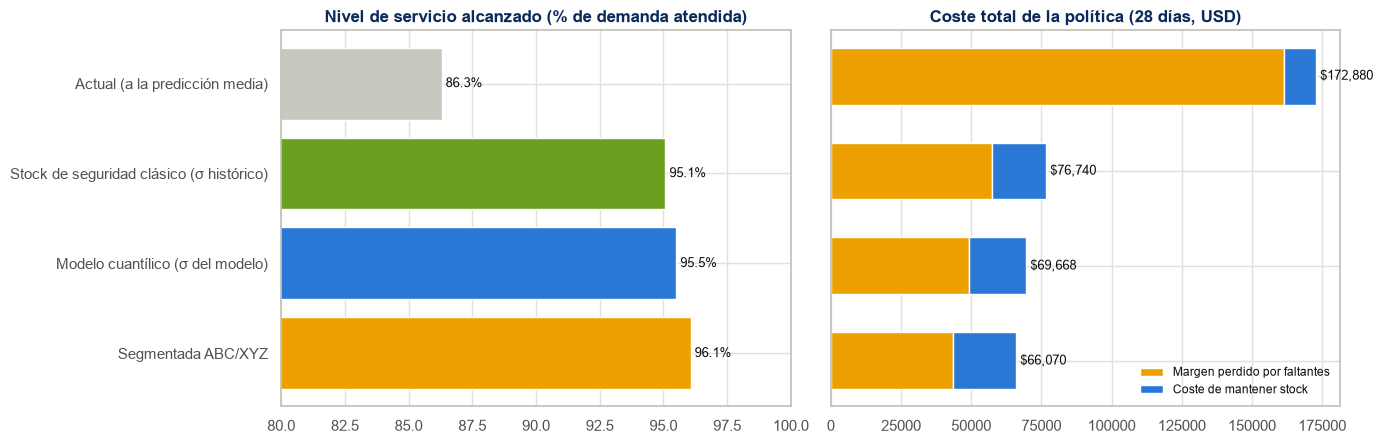

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
nombres = list(comparacion.index)
colores = ['#c9c8c0', DSMARKET_GREEN, DSMARKET_BLUE, DSMARKET_GOLD]

axes[0].barh(nombres[::-1], comparacion['nivel de servicio %'][::-1], color=colores[::-1])
axes[0].set_xlim(80, 100)
axes[0].set_title('Nivel de servicio alcanzado (% de demanda atendida)', color=DSMARKET_NAVY, fontweight='bold')
for i, v in enumerate(comparacion['nivel de servicio %'][::-1]):
    axes[0].text(v, i, f' {v:.1f}%', va='center', fontsize=9)

anchura = 0.6
axes[1].barh(nombres[::-1], comparacion['margen perdido USD'][::-1], anchura,
             color=DSMARKET_GOLD, label='Margen perdido por faltantes')
axes[1].barh(nombres[::-1], comparacion['mantenimiento USD'][::-1], anchura,
             left=comparacion['margen perdido USD'][::-1], color=DSMARKET_BLUE, label='Coste de mantener stock')
axes[1].set_title('Coste total de la política (28 días, USD)', color=DSMARKET_NAVY, fontweight='bold')
axes[1].legend(frameon=False, fontsize=8.5)
axes[1].set_yticklabels([])
for i, v in enumerate(comparacion['coste total USD'][::-1]):
    axes[1].text(v, i, f' ${v:,.0f}', va='center', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo — la política actual pierde plata por faltantes, no por exceso:**

| Política | Servicio | Coste total (28 días) | Ahorro |
|---|---|---|---|
| Actual (a la predicción media) | 86,3% | $172.880 | — |
| Stock de seguridad clásico | 95,1% | $76.740 | 55,6% |
| Modelo cuantílico | 95,5% | $69.668 | 59,7% |
| **Segmentada ABC/XYZ** | **96,1%** | **$66.070** | **61,8%** |

Tres lecturas:

1. **Pedir la predicción media atiende solo el 86,3% de la demanda y cuesta $172.880 en cuatro semanas** — de los cuales **$161.353 son margen perdido** por faltantes y apenas $11.527 el coste de mantener stock. La política actual no es cara por inmovilizar capital: es cara porque **deja de vender**. Son 162.189 unidades que el cliente quiso comprar y no encontró.

2. **Cualquier política con stock de seguridad ahorra más del 55%.** Es el mensaje más simple y más rentable de todo el proyecto, y no requiere machine learning: requiere aceptar que hay que stockear por encima del pronóstico.

3. **El stock de seguridad calculado con el modelo cuantílico le gana al clásico por un 9,2%** ($69.668 contra $76.740), con un nivel de servicio ligeramente mejor. Ahí sí es donde aporta el modelo de la Tarea 3: no en predecir mejor el promedio, sino en **estimar mejor la incertidumbre**.

La segmentación ABC/XYZ suma otro 5% sobre eso, subiendo el servicio al 96,1%: pone el stock donde el negocio lo necesita en vez de repartirlo parejo.

## 5. La curva servicio-coste: cuánto cuesta cada punto de servicio

La comparación anterior fija el nivel de servicio en 90% y compara formas de llegar ahí. La otra pregunta —la que en realidad decide el negocio— es **a qué nivel de servicio conviene apuntar**. Recorremos la curva completa.

In [8]:
NIVELES = [0.50, 0.70, 0.80, 0.85, 0.90, 0.95, 0.98, 0.99]
sims_nivel = {sl: simular(lambda t, z=norm.ppf(sl) if sl > 0.5 else 0.0: nivel_objetivo(t, sig_mod_ext, z))
              for sl in NIVELES}

def costes(sl, margen=MARGEN, tasa=TASA_MANTENIMIENTO, merma=0.0):
    r = sims_nivel[sl]; a = activo
    cu = precio * (1 - margen)
    perdido = (r['perdido'][a] * precio[a] * margen).sum()
    mantener = (r['inv_medio'][a] * cu[a]).sum() * tasa / 365 * H
    descarte = (r['remanente'][a] * cu[a]).sum() * merma
    return {'objetivo': sl, 'servicio real %': r['servido'][a].sum()/demanda[a].sum()*100,
            'margen perdido': perdido, 'mantenimiento': mantener, 'merma': descarte,
            'coste total': perdido + mantener + descarte,
            'inventario medio': r['inv_medio'][a].sum(), 'remanente': r['remanente'][a].sum()}

curva = pd.DataFrame([costes(sl) for sl in NIVELES]).set_index('objetivo')
print(f"Nivel de servicio con menor coste total (sin merma): {curva['coste total'].idxmin():.0%}")
print()
Cu = np.median(precio) * MARGEN
Co = np.median(precio) * (1 - MARGEN) * TASA_MANTENIMIENTO / 365 * VENTANA
print("Newsvendor teórico, con estos supuestos:")
print(f"  Cu (margen perdido por unidad faltante):        {Cu:.3f} USD")
print(f"  Co (mantener una unidad sobrante {VENTANA} días):      {Co:.4f} USD")
print(f"  nivel de servicio óptimo = Cu/(Cu+Co) =        {Cu/(Cu+Co):.1%}")
curva.round(1)

Nivel de servicio con menor coste total (sin merma): 99%

Newsvendor teórico, con estos supuestos:
  Cu (margen perdido por unidad faltante):        1.062 USD
  Co (mantener una unidad sobrante 9 días):      0.0196 USD
  nivel de servicio óptimo = Cu/(Cu+Co) =        98.2%


,servicio real %,margen perdido,mantenimiento,merma,coste total,inventario medio,remanente
objetivo,,,,,,,
0.50,86.3,161353.1,11526.6,0.0,172879.6,199105.8,147183.4
0.70,91.4,97977.8,15010.3,0.0,112988.0,254676.7,200675.1
0.80,93.5,72848.2,17228.2,0.0,90076.3,289997.6,235334.5
0.85,94.5,61074.9,18621.5,0.0,79696.5,312172.9,257184.9
0.90,95.5,49269.0,20401.1,0.0,69670.1,340537.2,285220.9
0.95,96.6,36588.1,23082.9,0.0,59671.1,383303.0,327584.2
0.98,97.5,26862.9,26143.6,0.0,53006.5,432129.7,376087.5
0.99,97.9,22232.4,28201.5,0.0,50433.8,464976.3,408785.5


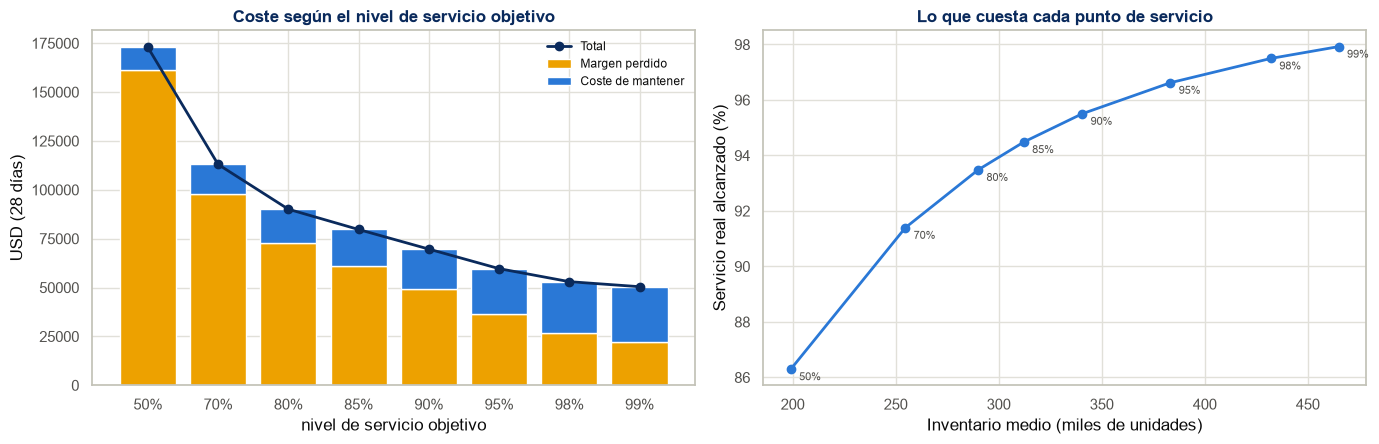

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
x = [f"{s:.0%}" for s in curva.index]
axes[0].bar(x, curva['margen perdido'], color=DSMARKET_GOLD, label='Margen perdido')
axes[0].bar(x, curva['mantenimiento'], bottom=curva['margen perdido'], color=DSMARKET_BLUE,
            label='Coste de mantener')
axes[0].plot(x, curva['coste total'], color=DSMARKET_NAVY, marker='o', linewidth=2, label='Total')
axes[0].set_title('Coste según el nivel de servicio objetivo', color=DSMARKET_NAVY, fontweight='bold')
axes[0].set_xlabel('nivel de servicio objetivo'); axes[0].set_ylabel('USD (28 días)')
axes[0].legend(frameon=False, fontsize=8.5)

ax2 = axes[1]
ax2.plot(curva['inventario medio']/1000, curva['servicio real %'], color=DSMARKET_BLUE,
         marker='o', linewidth=2)
for sl, row in curva.iterrows():
    ax2.annotate(f"{sl:.0%}", (row['inventario medio']/1000, row['servicio real %']),
                 textcoords='offset points', xytext=(6, -8), fontsize=8, color='#52514e')
ax2.set_xlabel('Inventario medio (miles de unidades)'); ax2.set_ylabel('Servicio real alcanzado (%)')
ax2.set_title('Lo que cuesta cada punto de servicio', color=DSMARKET_NAVY, fontweight='bold')
plt.tight_layout(); plt.show()

### 5.1. Sensibilidad: qué supuesto manda de verdad

El resultado anterior depende de dos números que **no tenemos** y que hay que pedirle a Finanzas: el margen bruto y el coste de que sobre stock. Recorremos los dos para ver cuál mueve la recomendación.

El coste de sobrante tiene dos componentes: el financiero (mantener capital inmovilizado, que es el que ya está en el cálculo) y la **merma** — la fracción del sobrante que directamente se pierde por caducidad, deterioro o falta de espacio. Para productos frescos la merma es el componente dominante, y no la conocemos.

In [10]:
filas = []
for merma in [0.0, 0.02, 0.05, 0.10, 0.20]:
    t = pd.DataFrame([costes(sl, merma=merma) for sl in NIVELES]).set_index('objetivo')
    filas.append({'merma sobre el remanente': f"{merma:.0%}", 'nivel óptimo': f"{t['coste total'].idxmin():.0%}",
                  'coste en el óptimo': t['coste total'].min(), 'coste al 90%': t.loc[0.90, 'coste total'],
                  'coste a la media (50%)': t.loc[0.50, 'coste total']})
sens_merma = pd.DataFrame(filas)

filas = []
for m in [0.10, 0.15, 0.25, 0.35]:
    t = pd.DataFrame([costes(sl, margen=m) for sl in NIVELES]).set_index('objetivo')
    filas.append({'margen bruto': f"{m:.0%}", 'nivel óptimo': f"{t['coste total'].idxmin():.0%}",
                  'coste en el óptimo': t['coste total'].min()})
sens_margen = pd.DataFrame(filas)
print("Sensibilidad a la merma:"); print(sens_merma.round(0).to_string(index=False))
print("\nSensibilidad al margen bruto (sin merma):"); print(sens_margen.round(0).to_string(index=False))

Sensibilidad a la merma:
merma sobre el remanente nivel óptimo  coste en el óptimo  coste al 90%  coste a la media (50%)
                      0%          99%             50434.0       69670.0                172880.0
                      2%          99%             76575.0       87663.0                181785.0
                      5%          95%            111643.0      114651.0                195143.0
                     10%          90%            159633.0      159633.0                217406.0
                     20%          80%            237035.0      249595.0                261932.0

Sensibilidad al margen bruto (sin merma):
margen bruto nivel óptimo  coste en el óptimo
         10%          98%             42117.0
         15%          99%             45301.0
         25%          99%             50434.0
         35%          99%             55567.0


**Hallazgo — el nivel de servicio óptimo lo decide la merma, no el margen:**

Con los supuestos base (margen 25%, coste de mantenimiento 25% anual, **sin merma**) el óptimo está en el **99%**, y el newsvendor teórico lo confirma: 98,2%. La razón es aritmética — mantener una unidad nueve días cuesta $0,0196, y perder una venta cuesta $1,06. Con esa relación, casi cualquier cantidad de stock se paga sola.

Pero ese cálculo asume que **el sobrante conserva su valor**, y eso es falso para todo lo fresco. Al agregar merma la recomendación se mueve mucho:

| Merma sobre el remanente | Nivel de servicio óptimo |
|---|---|
| 0% | 99% |
| 2% | 99% |
| 5% | 95% |
| 10% | 90% |
| **20%** | **80%** |

En cambio, mover el **margen bruto entre el 10% y el 35% deja el óptimo prácticamente donde estaba** (98-99%).

**La conclusión práctica para Paul es concreta y accionable:** no hace falta discutir el margen para fijar la política — hace falta **medir la tasa de merma por categoría**. Es un solo número por categoría, probablemente ya esté en los sistemas de DSMarket, y decide si el objetivo correcto es el 80% o el 99%. Mientras no lo tengamos, la recomendación prudente es diferenciar: nivel alto para lo no perecedero (ACCESORIES, HOME_&_GARDEN, donde el sobrante se vende la semana siguiente) y moderado para lo fresco de SUPERMARKET.

## 6. ¿Sirve el modelo para reponer? El test que nos contradijo

En la Tarea 3 medimos el error de predicción por segmento y sacamos una conclusión que parecía obvia: el modelo acierta en el núcleo estable (RMSSE 0,77) y falla en la cola larga (RMSSE 1,29, peor que el naive), así que **la cola larga no debería reponerse con predicción** sino con una regla empírica.

Es una afirmación comprobable, así que la comprobamos. Simulamos la misma política de dos formas:

- **Con modelo:** nivel objetivo = predicción + stock de seguridad del modelo cuantílico.
- **Sin modelo:** nivel objetivo = **percentil 90 empírico** de la demanda histórica en ventanas de 9 días. Sin predicción, sin features, sin entrenamiento: puro histórico.

Si nuestra conclusión de la Tarea 3 fuera correcta, el modelo debería ganar en el núcleo estable y perder en la cola larga.

In [11]:
hist_largo = V[:, s-180:s].astype(np.float64)
ventanas_hist = np.lib.stride_tricks.sliding_window_view(hist_largo, VENTANA, axis=1).sum(axis=2)
percentil_empirico = np.percentile(ventanas_hist, 90, axis=1)

nivel_con_modelo = lambda t: nivel_objetivo(t, sig_mod_ext, Z[0.90])
nivel_sin_modelo = lambda t: percentil_empirico

sim_con, sim_sin = simular(nivel_con_modelo), simular(nivel_sin_modelo)

def por_segmento(r, etiquetas, nombre_politica):
    salida = []
    for et in pd.unique(etiquetas):
        k = (etiquetas == et) & activo
        perdido = (r['perdido'][k] * precio[k] * MARGEN).sum()
        mantener = (r['inv_medio'][k] * costo_unitario[k]).sum() * TASA_MANTENIMIENTO / 365 * H
        salida.append({'segmento': et, 'política': nombre_politica,
                       'servicio %': r['servido'][k].sum()/demanda[k].sum()*100,
                       'coste USD': perdido + mantener})
    return salida

etq_arq = np.array([NOM_ARQ[c] for c in meta['cluster_k5'].values])
etq_xyz = np.array([f'XYZ · {c}' for c in clase_xyz])
filas = []
for r, nom in [(sim_con, 'Con modelo'), (sim_sin, 'Sin modelo (empírico)')]:
    filas += por_segmento(r, etq_arq, nom) + por_segmento(r, etq_xyz, nom)
seg = pd.DataFrame(filas)
tabla_seg = seg.pivot(index='segmento', columns='política', values=['servicio %', 'coste USD'])
tabla_seg['ahorro del modelo %'] = ((tabla_seg[('coste USD','Sin modelo (empírico)')] -
                                     tabla_seg[('coste USD','Con modelo')]) /
                                    tabla_seg[('coste USD','Sin modelo (empírico)')] * 100)
tabla_seg.round(1)

servicio %                        coste USD  \
política           Con modelo Sin modelo (empírico) Con modelo   
segmento                                                         
0 · Premium              94.8                  95.1     8988.0   
1 · Núcleo estable       95.7                  96.7    26913.8   
2 · Cola larga           94.0                  92.5     8414.3   
3 · Fin de semana        95.8                  95.4    17380.9   
4 · Fin de año           95.5                  95.8     7971.4   
XYZ · X                  97.0                  97.8    25002.2   
XYZ · Y                  96.0                  96.3    21898.7   
XYZ · Z                  84.7                  83.1    22767.5   

                                         ahorro del modelo %  
política           Sin modelo (empírico)                      
segmento                                                      
0 · Premium                       8975.4                -0.1  
1 · Núcleo estable               24951.0                -7.9  
2 · Cola larga                   10430.6                19.3  
3 · Fin de semana                17775.4                 2.2  
4 · Fin de año                    8281.4                 3.7  
XYZ · X                          22364.6               -11.8  
XYZ · Y                          22592.8                 3.1  
XYZ · Z                          25456.5                10.6

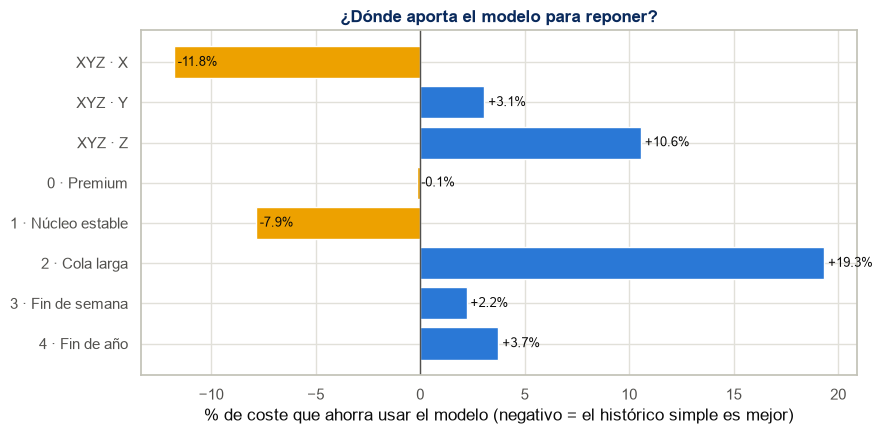

In [12]:
orden_seg = [s_ for s_ in tabla_seg.index if s_.startswith('XYZ')] + \
            [s_ for s_ in tabla_seg.index if not s_.startswith('XYZ')]
valores = tabla_seg.loc[orden_seg, 'ahorro del modelo %']
fig, ax = plt.subplots(figsize=(9, 4.5))
colores = [DSMARKET_BLUE if v > 0 else DSMARKET_GOLD for v in valores]
ax.barh(orden_seg[::-1], valores[::-1], color=colores[::-1])
ax.axvline(0, color='#52514e', linewidth=1)
ax.set_xlabel('% de coste que ahorra usar el modelo (negativo = el histórico simple es mejor)')
ax.set_title('¿Dónde aporta el modelo para reponer?', color=DSMARKET_NAVY, fontweight='bold')
for i, v in enumerate(valores[::-1]):
    ax.text(v, i, f' {v:+.1f}%', va='center', fontsize=9)
plt.tight_layout(); plt.show()

**Hallazgo — nuestra conclusión de la Tarea 3 era exactamente al revés, y conviene explicar por qué:**

| Segmento | Ahorro de usar el modelo |
|---|---|
| XYZ · X (demanda estable) | **−11,8%** (el histórico simple es mejor) |
| XYZ · Y | +3,1% |
| XYZ · Z (demanda errática) | **+10,6%** |
| 1 · Núcleo estable | **−7,9%** |
| 2 · Cola larga | **+19,3%** |

En la Tarea 3 dijimos que el modelo funcionaba en el núcleo estable (RMSSE 0,77) y no servía en la cola larga (RMSSE 1,29), y de ahí dedujimos que la cola larga debía reponerse con una regla empírica. **La simulación dice lo contrario: el modelo aporta un 19,3% justamente en la cola larga, y pierde un 7,9% en el núcleo estable.**

La explicación tiene que ver con qué mide cada cosa:

- El **RMSSE mide el acierto del pronóstico puntual, día a día**. La política de reposición no usa eso: usa la **distribución de la demanda acumulada en nueve días**. Son dos preguntas distintas y no tienen por qué ordenarse igual.
- Para una serie **estable y de alto volumen**, el percentil empírico de las ventanas históricas de nueve días es un estimador excelente: hay muchos datos, el comportamiento no cambia, y no asume ninguna forma de distribución. Nuestro cálculo, en cambio, arma la dispersión de nueve días sumando varianzas diarias **asumiendo independencia entre días** — y esa suposición subestima la variabilidad real cuando hay autocorrelación, que es mayor precisamente en las series de alto volumen.
- Para una serie **errática**, el percentil empírico de 180 días es ruidoso y está desactualizado. El modelo, que condiciona en el nivel reciente y el calendario, sí aporta.

**La lección metodológica, que va a la memoria:** *una métrica de error de predicción no es un sustituto de la métrica de negocio.* Elegir la política de reposición mirando el RMSSE nos habría llevado a la decisión opuesta a la correcta en dos segmentos. La forma de decidir es simular la política y medir el resultado económico — que es exactamente lo que hicimos acá.

## 7. La política recomendada

El resultado anterior sugiere una política **híbrida**: usar el histórico donde es suficiente y el modelo donde aporta. La probamos contra las dos alternativas puras.

In [13]:
usa_empirico = (clase_xyz == 'X')
nivel_hibrido = lambda t: np.where(usa_empirico, percentil_empirico, nivel_con_modelo(t))
sim_hib = simular(nivel_hibrido)

finales = pd.DataFrame([economia(sim_con, 'Solo modelo'),
                        economia(sim_sin, 'Solo percentil empírico'),
                        economia(sim_hib, 'Híbrida (empírico en X, modelo en Y/Z)'),
                        economia(resultados['Actual (a la predicción media)'], 'Actual (referencia)')]
                       ).set_index('política')
finales.round(1)

,nivel de servicio %,unidades perdidas,inventario medio (uds),margen perdido USD,mantenimiento USD,coste total USD,remanente final (uds)
política,,,,,,,
Solo modelo,95.5,53207.8,340542.9,49267.0,20401.4,69668.4,285226.5
Solo percentil empírico,95.9,47969.2,383913.3,48686.0,21727.8,70413.9,332082.1
"Híbrida (empírico en X, modelo en Y/Z)",96.0,47529.1,367667.4,45533.3,21497.5,67030.8,315964.8
Actual (referencia),86.3,162188.7,199105.8,161353.1,11526.6,172879.6,147183.4


**La política que proponemos: híbrida y segmentada.**

| Política | Servicio | Coste total (28 días) |
|---|---|---|
| Actual (referencia) | 86,3% | $172.880 |
| Solo modelo | 95,5% | $69.668 |
| Solo percentil empírico | 95,9% | $70.414 |
| **Híbrida (empírico en X, modelo en Y/Z)** | **96,0%** | **$67.031** |

La híbrida **domina a las dos alternativas puras**: mejor nivel de servicio *y* menor coste que cualquiera de las dos por separado. Es un 3,8% mejor que la mejor política pura y un **61% mejor que la política actual**.

En términos operativos, la propuesta se resume así:

| Segmento | Cómo se calcula el nivel objetivo | Servicio sugerido | Revisión |
|---|---|---|---|
| **AX** (56% de la facturación) | Percentil empírico de ventanas de 9 días | 95-98% | Semanal, automática |
| **AY, AZ** | Modelo: predicción + p90 | 90-95% | Semanal, automática |
| **BX** | Percentil empírico | 95% | Semanal, automática |
| **BY, BZ** | Modelo | 85-90% | Semanal, automática |
| **CX, CY** | Percentil empírico | 85-90% | Quincenal |
| **CZ** (28% del catálogo, 3,5% de la facturación) | Regla de stock mínimo, sin predicción | 80% | Quincenal + revisión de surtido |

Dos aclaraciones honestas sobre estos números:

1. **Los ahorros son del ejercicio simulado, no una promesa.** La simulación usa la demanda real observada, lo cual es lo correcto para comparar políticas entre sí, pero asume que la demanda no habría cambiado con más disponibilidad en góndola. En la realidad, tener producto disponible probablemente *aumente* las ventas — así que la comparación entre políticas es válida, pero el ahorro absoluto es una estimación.
2. **La comparación se hizo sobre cuatro semanas de marzo-abril.** Por lo que vimos en la Tarea 3, en temporada alta el modelo se degrada: estos resultados no se pueden extrapolar sin más a noviembre y diciembre.

## 8. Cómo se lleva esto a producción: diseño del servicio

*(Sección opcional del enunciado — es un diseño, no una implementación.)*

El cálculo de la sección 7 no sirve de nada si vive en un notebook. La forma natural de integrarlo con los sistemas de DSMarket es un servicio que responda una sola pregunta: **¿cuánto pido de este producto para esta tienda?**

### Arquitectura propuesta

```
                   ┌──────────────────────────────┐
   ventas diarias  │  1. Ingesta y features       │  batch nocturno
   precios         │     (ventas, precios,        │
   calendario      │      calendario, clusters)   │
                   └──────────────┬───────────────┘
                                  ▼
                   ┌──────────────────────────────┐
                   │  2. Entrenamiento semanal    │  ~2 min por modelo
                   │     LightGBM media + p90     │  (domingo de madrugada)
                   └──────────────┬───────────────┘
                                  ▼
                   ┌──────────────────────────────┐
                   │  3. Predicción diaria        │  28 días x 30.490 series
                   │     → tabla de predicciones  │
                   └──────────────┬───────────────┘
                                  ▼
   parámetros ───► ┌──────────────────────────────┐ ◄─── inventario actual
   (R, L, servicio)│  4. API de reposición        │      (sistema de tienda)
                   │     calcula S y sugiere pedido│
                   └──────────────┬───────────────┘
                                  ▼
                        ERP / sistema de compras
```

### Contrato de la API

**`POST /reposicion/sugerencia`**

```json
{
  "tienda": "NYC_1",
  "fecha_revision": "2016-04-25",
  "productos": [
    {"item": "SUPERMARKET_3_069", "stock_actual": 42, "en_transito": 0}
  ],
  "parametros": {"dias_revision": 7, "lead_time": 2, "nivel_servicio": 0.95}
}
```

```json
{
  "fecha_revision": "2016-04-25",
  "cobertura_hasta": "2016-05-04",
  "sugerencias": [
    {
      "item": "SUPERMARKET_3_069",
      "demanda_esperada": 86.4,
      "nivel_objetivo": 118.0,
      "pedido_sugerido": 76,
      "nivel_servicio_aplicado": 0.95,
      "segmento": "AX",
      "confianza": "alta",
      "motivo": "serie estable, política empírica"
    }
  ]
}
```

Tres decisiones de diseño que conviene justificar:

- **La API no predice, lee predicciones.** El modelo corre en batch y deja las predicciones en tabla; la API solo resuelve la aritmética de la política. Así responde en milisegundos y el pico de carga de las revisiones semanales no depende del modelo.
- **Los parámetros viajan en la petición**, no están fijos en el código. Permite que Finanzas cambie el nivel de servicio por categoría sin tocar el servicio, y que se pruebe un cambio en unas tiendas antes de extenderlo.
- **Cada sugerencia se explica.** Devolver el segmento y el motivo es lo que hace que un encargado de tienda confíe en el número en vez de ignorarlo — y en la práctica es lo que decide si el proyecto se usa o no.

### Qué hay que monitorear

| Métrica | Para qué | Alerta |
|---|---|---|
| Nivel de servicio real vs objetivo | El sistema cumple lo que promete | Desvío > 3 pp durante 2 semanas |
| Sesgo de la predicción | Detecta el problema de la Tarea 3 | Sesgo > ±3% sostenido |
| Cobertura real del p90 | El intervalo sigue calibrado | Fuera del rango 87-93% |
| Rotación e inventario medio | El coste no se dispara | Inventario > 15% sobre el plan |
| % de sugerencias modificadas a mano | Si el equipo confía en el sistema | > 30% |

## 9. De tres ciudades al resto del país

*(Sección opcional del enunciado.)*

El proyecto piloto cubre 10 tiendas. La pregunta de Michelle es qué pasa al multiplicar por cien.

**Lo que escala sin problema.** El modelo es global: una sola instancia aprende de todas las series. Pasar de 30.490 a 3 millones de series multiplica el volumen de datos, pero no la complejidad del sistema — y el entrenamiento es paralelizable por partición temporal. Con la infraestructura adecuada (Spark o Dask para features, entrenamiento distribuido), el coste crece de forma aproximadamente lineal, no explosiva.

**Lo que NO escala directamente, y es lo importante:**

1. **Una tienda nueva no tiene historia.** Es el problema de arranque en frío, y es donde la Tarea 2 deja el aporte más concreto: en vez de esperar un año de datos, se asigna la tienda nueva al **grupo de comportamiento** que le corresponda por tipo de zona, y se arranca con el perfil de demanda de ese grupo. Recordemos el hallazgo: el perfil de demanda **cruza fronteras de ciudad** (Tribeca se comporta como Boston), así que el criterio de asignación debe ser el tipo de barrio, no la geografía.
2. **Los supuestos económicos no son nacionales.** Márgenes, costes logísticos y plazos de entrega cambian por región. Los parámetros de la política tienen que ser configurables por tienda o por grupo, no constantes.
3. **La validación tiene que ser continua.** Con 10 tiendas se puede revisar a mano; con 1.000 hace falta el monitoreo automático de la sección 8, o los problemas se detectan cuando ya costaron dinero.

**Plan por fases sugerido:**

| Fase | Alcance | Objetivo |
|---|---|---|
| 1 (2 meses) | 2 tiendas piloto, categoría SUPERMARKET | Validar el nivel de servicio real contra el simulado y medir la merma real |
| 2 (3 meses) | Las 10 tiendas, todas las categorías | Ajustar parámetros por categoría; medir el ahorro real contra la línea base |
| 3 (6 meses) | Despliegue nacional por grupos de comportamiento | Extender por grupo, no por ciudad; una tienda nueva arranca con el perfil de su grupo |

La fase 1 no es opcional: **la merma real es el parámetro que decide la política entera** (sección 5.1) y hoy no lo tenemos medido.

## 10. Estado de la Tarea 4 y qué necesitamos de DSMarket

**Lo que queda propuesto y cuantificado:**

| Pedido del enunciado | Resultado |
|---|---|
| Cómo aplicar los modelos a la reposición semanal/diaria | Política de revisión periódica (R=7, L=2) con nivel objetivo híbrido, simulada sobre 30.490 series y 4 semanas reales |
| Stock mínimo | Stock de seguridad diferenciado por celda ABC/XYZ, con el nivel de servicio como parámetro de negocio, no del modelo |
| Minimizar remanente | Curva servicio-coste completa; el nivel óptimo va del 80% al 99% según la merma (sección 5.1) |
| Diseño de API *(opcional)* | Sección 8: arquitectura, contrato, y métricas de monitoreo |
| Plan de escalabilidad *(opcional)* | Sección 9: qué escala solo, qué no, y plan en tres fases |

**El resultado central:** pasar de "pedir lo que dice el pronóstico" a una política con stock de seguridad calculado sube el nivel de servicio del 86,3% al 96,0% y **reduce el coste total un 61%** en el período simulado. La mayor parte de ese ahorro no viene del modelo sino de una idea de gestión —stockear por encima del pronóstico— y el modelo aporta el refinamiento: estimar bien *cuánto* por encima, y en qué productos.

**Los tres números que necesitamos de DSMarket para cerrar la propuesta:**

1. **La tasa de merma por categoría.** Es el parámetro que decide el nivel de servicio objetivo, y hoy es el único supuesto que puede mover la recomendación de punta a punta (del 80% al 99%).
2. **El margen bruto real por categoría.** Menos crítico —vimos que mueve poco el óptimo— pero necesario para dimensionar el ahorro en dinero.
3. **El plazo de entrega real por tienda y proveedor.** Usamos 2 días para todo; si en la práctica varía, el stock de seguridad tiene que variar con él.

**Lo que queda pendiente y conviene decir antes de que lo pregunten:**

- La política **no está validada en temporada alta**, por la limitación heredada de la Tarea 3. Antes de aplicarla en noviembre-diciembre hay que repetir esta simulación sobre esos meses, con la regla de días de cierre incorporada.
- La simulación **no modela restricciones de espacio en góndola**, que en la práctica son un tope duro. Con niveles de servicio del 95-99% el inventario medio sube un 70-130%, y eso puede simplemente no entrar en la tienda.
- **No modelamos el efecto de la disponibilidad sobre la demanda.** Es una simplificación estándar, pero conviene tenerla presente: los ahorros estimados son probablemente conservadores por el lado de las ventas perdidas.